# 03 — Qiskit Fermions: fermionic operators, mappings, circuits and transpilation

[`qiskit-fermions`](https://github.com/Qiskit/qiskit-fermions) is a Qiskit add-on for **fermionic systems**, for example electrons in molecules and materials [[1]](https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/overview). Its core is written in Rust. It has these submodules:

| submodule | contents |
|---|---|
| `qiskit_fermions.operators` | `FermionOperator` (creation/annihilation), `MajoranaOperator`, interaction operators; FCIDump reader; commutators; term grouping |
| `qiskit_fermions.mappers` | fermion-to-qubit mappings (Jordan–Wigner) and a framework for new mappings |
| `qiskit_fermions.circuit` | `FermionicCircuit` and fermionic gates (`Evolution`, `InitializeModes`, `OrbitalRotation`, `PrepareSlaterDeterminant`, `UCC`, `UCJ`) |
| `qiskit_fermions.transpiler` | pass managers that convert a fermionic circuit into a qubit `QuantumCircuit` |
| `qiskit_fermions.linalg` | Givens-rotation decompositions |
| `qiskit_fermions.protocols` | duck-typed protocols (`_fermion_operator_`, `_majorana_operator_`, ...) and ffsim interoperability |

**Based on** (the examples are adapted; the Hubbard and H$_2$ examples are our own)

* qiskit-fermions guides: Overview [[1]](https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/overview), Design principles of operator representations [[2]](https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/operators), Map operator representations [[3]](https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/mappers), Work with fermionic circuits [[4]](https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/circuit), Transpile fermionic circuits [[5]](https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/transpilation), Optimize Slater determinant preparation [[6]](https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/merge-slater-determinant), Transpile an LUCJ ansatz [[7]](https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/lucj), How this package relates to ffsim [[8]](https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/ffsim)
* qiskit-fermions API reference: `operators` [[9]](https://quantum.cloud.ibm.com/docs/en/api/qiskit-fermions/operators), `mappers` [[10]](https://quantum.cloud.ibm.com/docs/en/api/qiskit-fermions/mappers), `circuit` [[11]](https://quantum.cloud.ibm.com/docs/en/api/qiskit-fermions/circuit), `transpiler` [[12]](https://quantum.cloud.ibm.com/docs/en/api/qiskit-fermions/transpiler)
* ffsim documentation: `ffsim.apply_unitary` [[13]](https://qiskit-community.github.io/ffsim/api/stubs/ffsim.apply_unitary.html), the LUCJ explanation [[14]](https://qiskit-community.github.io/ffsim/explanations/lucj.html), `ffsim.UCJOpSpinBalanced` [[15]](https://qiskit-community.github.io/ffsim/api/stubs/ffsim.UCJOpSpinBalanced.html)
* PySCF user guide: SCF methods [[16]](https://pyscf.org/user/scf.html), coupled-cluster theory [[17]](https://pyscf.org/user/cc.html)
* Source code: <https://github.com/Qiskit/qiskit-fermions> (guides in `docs/guides`)

Installation (as in the container definition `qiskit.def`):
```bash
pip install "qiskit-fermions[ffsim]"
```
The `ffsim` extra installs ffsim and PySCF. Section 10 uses ffsim for simulation in fermionic space and for the `UCC`/`UCJ` ansätze.

Versions: qiskit-fermions 0.2.0, qiskit 2.5.2, ffsim 0.0.80, PySCF 2.14.0. qiskit-fermions is an early pre-release, so its API can change.

**Contents**
1. Background: second quantization
2. Fermionic operators: construction, algebra, normal ordering
3. Majorana operators
4. Building Hamiltonians: Fermi–Hubbard and an H$_2$ molecule from an FCIDump
5. Fermion-to-qubit mapping: Jordan–Wigner and a custom mapper
6. Exact diagonalization in fixed particle-number sectors
7. Fermionic circuits and gates
8. Transpiling fermionic circuits to qubits
9. Ground-state energies with `StatevectorEstimator`: H$_2$ (UCC-type ansatz) and Hubbard (HVA)
10. ffsim integration: sparse eigensolvers, fermionic-space simulation, UCCSD and LUCJ ansätze
11. Summary and references

## 1. Background: second quantization

In second quantization, a many-fermion state is described by the **occupation numbers** of $N$ single-particle *modes* (spin-orbitals).
A basis state is $|n_0 n_1 \dots n_{N-1}\rangle$ with $n_j\in\{0,1\}$. The Pauli principle allows at most one fermion per mode.

The **creation** operator $a_j^\dagger$ fills mode $j$. The **annihilation** operator $a_j$ empties it.
They satisfy the canonical anti-commutation relations (CAR):

$$\{a_i, a_j^\dagger\} = \delta_{ij}, \qquad \{a_i, a_j\} = \{a_i^\dagger, a_j^\dagger\} = 0.$$

It follows that $(a_j^\dagger)^2 = 0$. The operator $n_j = a_j^\dagger a_j$ is the number operator of mode $j$.

A general electronic-structure Hamiltonian is
$$ H = \sum_{pq} h_{pq}\, a_p^\dagger a_q + \tfrac12 \sum_{pqrs} g_{pqrs}\, a_p^\dagger a_r^\dagger a_s a_q + E_\text{const}. $$
The **Fermi–Hubbard model** [[18]](https://qiskit-community.github.io/ffsim/api/stubs/ffsim.fermi_hubbard_1d.html) on a lattice is a simpler example. Here $t$ is the hopping amplitude, $U$ is the on-site interaction, $\langle ij\rangle$ are neighbouring sites and $\sigma$ is the spin:
$$ H = -t\sum_{\langle ij\rangle,\sigma}\left(a_{i\sigma}^\dagger a_{j\sigma} + a_{j\sigma}^\dagger a_{i\sigma}\right) + U\sum_i n_{i\uparrow} n_{i\downarrow}. $$

Qubits are not fermions: operators on different qubits *commute*.
A **fermion-to-qubit mapping** gives qubit operators that obey the CAR.
The Jordan–Wigner (JW) mapping [[3]](https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/mappers) does this with strings of Pauli $Z$ operators:
$$ a_j^\dagger \;\mapsto\; Z_0 \cdots Z_{j-1}\, \tfrac12 (X_j - iY_j), \qquad n_j \mapsto \tfrac12 (I - Z_j).$$

**Convention in this notebook (block-spin ordering).** With $n_\text{orb}$ spatial orbitals, modes $0,\dots,n_\text{orb}-1$ are spin-$\alpha$ ($\uparrow$) and modes $n_\text{orb},\dots,2n_\text{orb}-1$ are spin-$\beta$ ($\downarrow$). The FCIDump and Hartree–Fock helpers of the library use the same ordering.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import scipy.linalg as sla
import matplotlib.pyplot as plt

import qiskit, qiskit_fermions
print("qiskit         ", qiskit.__version__)
print("qiskit-fermions", qiskit_fermions.__version__)

qiskit          2.5.2
qiskit-fermions 0.2.0


## 2. Fermionic operators

`FermionOperator` is a sparse linear combination of products of creation and annihilation **actions** [[2]](https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/operators), [[9]](https://quantum.cloud.ibm.com/docs/en/api/qiskit-fermions/operators).
An action is a tuple `(is_creation, mode)`. The helpers `cre(j)` and `ann(j)` build actions.
The simplest constructor is `from_dict`. It maps a tuple of actions to a coefficient.
`format(op)` prints the operator in a readable form: `+j` means $a_j^\dagger$ and `-j` means $a_j$.

In [2]:
from qiskit_fermions.operators import FermionOperator, cre, ann

print(cre(3), ann(3))          # actions are plain tuples (is_creation, mode)

op = FermionOperator.from_dict(
    {
        (): 0.5,                                   # identity term
        (cre(0), ann(1)): 1.0,                     # a0^dag a1
        (cre(1), ann(0)): 1.0,                     # a1^dag a0
        (cre(0), cre(1), ann(1), ann(0)): 2.0,     # a0^dag a1^dag a1 a0  (= n0 n1)
    }
)
print(format(op))
print(str(op))          # compact
print(repr(op))         # copy-pasteable

(True, 3) (False, 3)
 5.000000e-1 +0.000000e0j * ()
  1.000000e0 +0.000000e0j * (+0 -1)
  2.000000e0 +0.000000e0j * (+0 +1 -1 -0)
  1.000000e0 +0.000000e0j * (+1 -0)
<FermionOperator with 4 terms>
FermionOperator.from_dict({((True, 1), (False, 0)): 1+0j, (): 0.5+0j, ((True, 0), (False, 1)): 1+0j, ((True, 0), (True, 1), (False, 1), (False, 0)): 2+0j})


### Arithmetic, composition and the adjoint

Operators support `+`, `-`, scalar `*` and `/`. There are two product operators:
* `a @ b` is the ordinary product $AB$.
* `a & b` is *composition* ("first `a`, then `b`"), which is $BA$.

The operator is stored in a compressed sparse format that allows duplicate terms. `.simplify()` combines the duplicates. `.adjoint()` returns the Hermitian conjugate.

In [3]:
a0  = FermionOperator.from_dict({(ann(0),): 1.0})
a0d = a0.adjoint()
a1d = FermionOperator.from_dict({(cre(1),): 1.0})

print("a0 @ a0^dag  :", format(a0 @ a0d))
print("a0 & a0^dag  :", format(a0 & a0d), "  (= a0^dag a0)")
print("(op + op).simplify():")
print(format((op + op).simplify()))
print("is_hermitian:", op.is_hermitian(), "| conserves N:", op.conserves_particle_number(),
      "| max rank:", op.max_rank(), "| support:", op.get_support())

a0 @ a0^dag  :   1.000000e0 +0.000000e0j * (-0 +0)
a0 & a0^dag  :   1.000000e0 +0.000000e0j * (+0 -0)   (= a0^dag a0)
(op + op).simplify():
  1.000000e0 +0.000000e0j * ()
  2.000000e0 +0.000000e0j * (+0 -1)
  4.000000e0 +0.000000e0j * (+0 +1 -1 -0)
  2.000000e0 +0.000000e0j * (+1 -0)
is_hermitian: True | conserves N: True | max rank: 4 | support: {0, 1}


### Normal ordering and the anti-commutation relations

`simplify()` merges only terms that are *exactly identical*. It does not apply the CAR.
`normal_ordered()` applies the CAR. It moves all creation operators to the left of all annihilation operators and sorts the modes.
The signs and the contractions $\delta_{ij}$ from the reordering are included.

`qiskit_fermions.operators.library` provides `commutator`, `anti_commutator` and `double_commutator`. The next cell checks the CAR.

In [4]:
from qiskit_fermions.operators.library import anti_commutator, commutator

ac = anti_commutator(a0, a0d)
print("{a0, a0^dag} raw:\n" + format(ac.simplify()))
print("{a0, a0^dag} normal ordered:\n" + format(ac.normal_ordered().simplify()))
print("{a0, a1^dag} normal ordered:", repr(anti_commutator(a0, a1d).normal_ordered().simplify()))
print("{a0^dag, a0^dag} normal ordered:", repr(anti_commutator(a0d, a0d).normal_ordered().simplify()))

# Number operators commute: [n0, n1] = 0
n0 = FermionOperator.from_dict({(cre(0), ann(0)): 1.0})
n1 = FermionOperator.from_dict({(cre(1), ann(1)): 1.0})
print("[n0, n1] =", repr(commutator(n0, n1).normal_ordered().simplify()))
# and n0 is idempotent: n0^2 = n0
print("n0@n0 - n0 =", repr((n0 @ n0 - n0).normal_ordered().simplify()))

{a0, a0^dag} raw:
  1.000000e0 +0.000000e0j * (-0 +0)
  1.000000e0 +0.000000e0j * (+0 -0)
{a0, a0^dag} normal ordered:
  1.000000e0 +0.000000e0j * ()
{a0, a1^dag} normal ordered: FermionOperator.from_dict({})
{a0^dag, a0^dag} normal ordered: FermionOperator.from_dict({})
[n0, n1] = FermionOperator.from_dict({})
n0@n0 - n0 = FermionOperator.from_dict({})


In [5]:
# Normal ordering a term that is not normal ordered: a0 a0^dag = 1 - a0^dag a0
x = FermionOperator.from_dict({(ann(0), cre(0)): 1.0, (cre(1), cre(0), ann(1), ann(0)): 2.0})
print("default (descending):\n" + format(x.normal_ordered()))
print("sandwich=True:\n" + format(x.normal_ordered(sandwich=True)))

# equiv() is the tolerance-based mathematical comparison; == compares stored data exactly
y = FermionOperator.from_dict({(): 1.0, (cre(0), ann(0)): -1.0, (cre(1), cre(0), ann(1), ann(0)): 2.0})
print("x.normal_ordered().equiv(y):", x.normal_ordered().equiv(y))

# relabeling modes, iterating over terms
print(list(op.relabel_modes([5, 7]).iter_terms())[:2])

default (descending):
  1.000000e0 +0.000000e0j * ()
 -1.000000e0 -0.000000e0j * (+0 -0)
  2.000000e0 +0.000000e0j * (+1 +0 -1 -0)
sandwich=True:
  1.000000e0 +0.000000e0j * ()
 -1.000000e0 -0.000000e0j * (+0 -0)
 -2.000000e0 -0.000000e0j * (+0 +1 -1 -0)
x.normal_ordered().equiv(y): True
[([(True, 7), (False, 5)], (1+0j)), ([], (0.5+0j))]


## 3. Majorana operators

Each fermionic mode can be written with two Hermitian **Majorana** operators, $\gamma_j = a_j^\dagger + a_j$ and $\gamma'_j = i(a_j^\dagger - a_j)$. They satisfy $\{\gamma_i,\gamma_j\} = 2\delta_{ij}$.

* `MajoranaOperator` stores products of Majorana operators.
* `gamma(j, is_prime)` builds one Majorana operator.
* `fermion_to_majorana` and `majorana_to_fermion` convert between the two representations.

As for `FermionOperator`, `normal_ordered()` applies the algebra (for example $\gamma\gamma=1$).

In [6]:
from qiskit_fermions.operators import MajoranaOperator, gamma
from qiskit_fermions.mappers.library import fermion_to_majorana, majorana_to_fermion

m = fermion_to_majorana(n0)
print("n0 in Majoranas (raw):\n" + format(m.simplify()))
print("n0 in Majoranas (normal ordered):\n" + format(m.normal_ordered().simplify()))
print("is_even (parity-preserving):", m.is_even())

# Round trip back to fermions
print("round trip equals n0:", majorana_to_fermion(m).normal_ordered().simplify().equiv(n0))

# Build a Majorana operator directly: i * gamma_0 gamma'_0 = 1 - 2 n_0  (the parity operator)
P0 = MajoranaOperator.from_dict({(gamma(0, False), gamma(0, True)): 1j})
print("i g0 g'0 -> fermions:\n" + format(majorana_to_fermion(P0).normal_ordered().simplify()))

n0 in Majoranas (raw):
 2.500000e-1 +0.000000e0j * (γ0 γ0)
  0.000000e0+2.500000e-1j * (γ0 γ'0)
  0.000000e0-2.500000e-1j * (γ'0 γ0)
 2.500000e-1 +0.000000e0j * (γ'0 γ'0)
n0 in Majoranas (normal ordered):
 5.000000e-1 +0.000000e0j * ()
  0.000000e0-5.000000e-1j * (γ'0 γ0)
is_even (parity-preserving): True
round trip equals n0: True
i g0 g'0 -> fermions:
 -1.000000e0 +0.000000e0j * ()
  2.000000e0 +0.000000e0j * (+0 -0)


## 4. Building Hamiltonians

### 4a. The 1D Fermi–Hubbard chain

We build an open chain of $L$ sites with block-spin ordering: mode $i$ is site $i\uparrow$, and mode $i+L$ is site $i\downarrow$.
We keep the hopping (kinetic) part and the interaction part as two operators, because later sections use them separately.

In [7]:
def hubbard_terms(L, t=1.0, U=4.0):
    # Return (hopping, interaction) FermionOperators of an open 1D Hubbard chain.
    hop = {}
    for s in (0, L):                       # spin-up block, spin-down block
        for i in range(L - 1):
            hop[(cre(s + i), ann(s + i + 1))] = -t
            hop[(cre(s + i + 1), ann(s + i))] = -t
    inter = {(cre(i), ann(i), cre(i + L), ann(i + L)): U for i in range(L)}
    return FermionOperator.from_dict(hop), FermionOperator.from_dict(inter)

L, t_hop, U_int = 4, 1.0, 4.0
H_hop, H_int = hubbard_terms(L, t_hop, U_int)
H_hub = (H_hop + H_int).simplify()
n_modes = 2 * L

print(H_hub, "on", n_modes, "modes")
print("Hermitian:", H_hub.is_hermitian(),
      "| conserves N:", H_hub.conserves_particle_number(),
      "| conserves (N_up, N_down):", H_hub.conserves_sector([L, L]))

<FermionOperator with 16 terms> on 8 modes
Hermitian: True | conserves N: True | conserves (N_up, N_down): True


### 4b. A molecular Hamiltonian from an FCIDump file: H$_2$/STO-3G

`FCIDump` reads the standard FCIDUMP text format. PySCF [[16]](https://pyscf.org/user/scf.html) and most quantum-chemistry codes can write this format.
The two-electron integrals are in chemists' notation $(ij|kl)$.
`FermionOperator.from_fcidump` builds the full second-quantized Hamiltonian, including the nuclear-repulsion constant.
Below we write the integrals of H$_2$ at $R=0.735$ Å to a temporary file. The system has 2 spatial orbitals (4 spin-orbitals) and 2 electrons.

Other constructors take triangular-packed integral arrays: `from_1body_tril_spin_sym`, `from_2body_tril_spin_sym` and their unrestricted `*_spin` variants.

In [8]:
import os, tempfile
from qiskit_fermions.operators.library import FCIDump

fcidump_text = '''&FCI NORB=2,NELEC=2,MS2=0,
  ORBSYM=1,1,
  ISYM=1,
 &END
  0.67571015  1  1  1  1
  0.18093120  2  1  2  1
  0.66458173  2  2  1  1
  0.69793770  2  2  2  2
 -1.25633907  1  1  0  0
 -0.47189601  2  2  0  0
  0.71996899  0  0  0  0
'''
path = os.path.join(tempfile.mkdtemp(), "h2.fcidump")
with open(path, "w") as f:
    f.write(fcidump_text)

fcidump = FCIDump.from_file(path)
print("norb:", fcidump.norb, "nelec:", fcidump.nelec, "ms2:", fcidump.ms2, "E_nuc:", fcidump.constant)
print("1-body (tril):", fcidump.get_one_body_tril_a())
print("2-body (tril):", fcidump.get_two_body_tril_aa())

H_h2 = FermionOperator.from_fcidump(fcidump)
print(H_h2, "| Hermitian:", H_h2.is_hermitian())

norb: 2 nelec: 2 ms2: 0 E_nuc: 0.71996899
1-body (tril): [-1.25633907  0.         -0.47189601]
2-body (tril): [0.67571015 0.         0.1809312  0.66458173 0.         0.6979377 ]
<FermionOperator with 37 terms> | Hermitian: True


The raw operator contains terms such as $a_0^\dagger a_0^\dagger a_0 a_0$. The Pauli principle makes these terms zero.
Normal ordering removes them and merges equivalent orderings. The operator then has 15 terms instead of 37.

In [9]:
H_h2_no = H_h2.normal_ordered().simplify()
print("terms before:", len(list(H_h2.iter_terms())), "-> after normal ordering:", len(list(H_h2_no.iter_terms())))
print(format(H_h2_no))

terms before: 37 -> after normal ordering: 15
 7.199690e-1 +0.000000e0j * ()
 -1.256339e0 +0.000000e0j * (+0 -0)
-4.718960e-1 +0.000000e0j * (+1 -1)
-4.836505e-1 +0.000000e0j * (+1 +0 -1 -0)
 -1.256339e0 +0.000000e0j * (+2 -2)
-6.757102e-1 -0.000000e0j * (+2 +0 -2 -0)
-1.809312e-1 -0.000000e0j * (+2 +0 -3 -1)
-6.645817e-1 -0.000000e0j * (+2 +1 -2 -1)
-1.809312e-1 -0.000000e0j * (+2 +1 -3 -0)
-4.718960e-1 +0.000000e0j * (+3 -3)
-1.809312e-1 -0.000000e0j * (+3 +0 -2 -1)
-6.645817e-1 -0.000000e0j * (+3 +0 -3 -0)
-1.809312e-1 -0.000000e0j * (+3 +1 -2 -0)
-6.979377e-1 -0.000000e0j * (+3 +1 -3 -1)
-4.836505e-1 +0.000000e0j * (+3 +2 -3 -2)


## 5. Fermion-to-qubit mapping

### Jordan–Wigner

`qiskit_fermions.mappers.library.jordan_wigner(op, num_qubits)` maps an operator to a Qiskit `SparseObservable` [[3]](https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/mappers), [[10]](https://quantum.cloud.ibm.com/docs/en/api/qiskit-fermions/mappers).
It accepts Fermion, Majorana, EdgeVertex and TransferVertex operators.
Under JW, mode $j$ is qubit $j$, and an occupied mode is $|1\rangle$.
`SparsePauliOp.from_sparse_observable` converts the result to a `SparsePauliOp`.

JW is the only built-in mapping in version 0.2.0. The `mappers` module has generic building blocks for other mappings (see below).

In [10]:
from qiskit.quantum_info import SparsePauliOp
from qiskit_fermions.mappers.library import jordan_wigner

print("n0      ->", jordan_wigner(n0, 2).simplify())
hop01 = FermionOperator.from_dict({(cre(0), ann(1)): 1.0, (cre(1), ann(0)): 1.0})
print("hopping ->", jordan_wigner(hop01, 2).simplify())
print("a0^dag a2 + h.c. (JW Z-string) ->",
      jordan_wigner(FermionOperator.from_dict({(cre(0), ann(2)): 1.0, (cre(2), ann(0)): 1.0}), 3).simplify())

qH_h2 = SparsePauliOp.from_sparse_observable(jordan_wigner(H_h2, 4).simplify())
qH_hub = SparsePauliOp.from_sparse_observable(jordan_wigner(H_hub, n_modes).simplify())
print("\nH2 qubit Hamiltonian:\n", qH_h2)
print("\nHubbard qubit Hamiltonian:", len(qH_hub), "Pauli terms on", qH_hub.num_qubits, "qubits")

n0      -> <SparseObservable with 2 terms on 2 qubits: (0.5+0j)() + (-0.5+0j)(Z_0)>
hopping -> <SparseObservable with 2 terms on 2 qubits: (0.5+0j)(X_1 X_0) + (0.5+0j)(Y_1 Y_0)>
a0^dag a2 + h.c. (JW Z-string) -> <SparseObservable with 2 terms on 3 qubits: (0.5+0j)(X_2 Z_1 X_0) + (0.5+0j)(Y_2 Z_1 Y_0)>

H2 qubit Hamiltonian:
 SparsePauliOp(['IIII', 'IIIZ', 'IIZZ', 'XXXX', 'YYXX', 'XXYY', 'YYYY', 'IZIZ', 'ZIIZ', 'IIZI', 'IZZI', 'ZIZI', 'IZII', 'ZZII', 'ZIII'],
              coeffs=[-0.090738  +0.j,  0.17218393+0.j,  0.12091263+0.j,  0.0452328 +0.j,
  0.0452328 +0.j,  0.0452328 +0.j,  0.0452328 +0.j,  0.16892754+0.j,
  0.16614543+0.j, -0.22559449+0.j,  0.16614543+0.j,  0.17448442+0.j,
  0.17218393+0.j,  0.12091263+0.j, -0.22559449+0.j])

Hubbard qubit Hamiltonian: 25 Pauli terms on 8 qubits


The JW mapping of the equivalent `MajoranaOperator` gives the same qubit operator. This is a consistency check.

In [11]:
jw_f = jordan_wigner(H_hub, n_modes).simplify()
jw_m = jordan_wigner(fermion_to_majorana(H_hub), n_modes).simplify()
print("Fermion vs Majorana route agree:",
      SparsePauliOp.from_sparse_observable(jw_f - jw_m).simplify(atol=1e-12).coeffs.size == 1
      and np.allclose(SparsePauliOp.from_sparse_observable(jw_f - jw_m).simplify(atol=1e-12).coeffs, 0))

Fermion vs Majorana route agree: True


### A custom mapping: the parity encoding

`map_fermion_action_generators(op, map_action, identity, compose)` loops over the terms of a `FermionOperator` [[3]](https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/mappers).
It builds the image of each action with the function `map_action`.
As an example we implement the **parity mapping**. In this mapping, qubit $j$ stores the parity $n_0\oplus\dots\oplus n_j$:
$$ a_j^\dagger \mapsto \tfrac12\left(Z_{j-1}X_j - iY_j\right) X_{j+1}\cdots X_{N-1},\qquad (Z_{-1}\equiv I). $$
The mapped Hamiltonian has different Pauli terms, but the **same spectrum** as the JW Hamiltonian.

In [12]:
from qiskit.quantum_info import SparseObservable
from qiskit_fermions.mappers import map_fermion_action_generators

def parity_mapper(num_qubits):
    def map_action(action):
        is_cre, j = action
        tail = "X" * (num_qubits - j - 1)
        tail_q = list(range(j + 1, num_qubits))
        sign = -1 if is_cre else +1                 # a^dag: (Z X - iY)/2,  a: (Z X + iY)/2
        zx = ("Z" if j > 0 else "") + "X"
        zx_q = ([j - 1] if j > 0 else []) + [j]
        return SparseObservable.from_sparse_list(
            [(zx + tail, zx_q + tail_q, 0.5), ("Y" + tail, [j] + tail_q, sign * 0.5j)],
            num_qubits=num_qubits,
        )
    return map_action

def parity(op, num_qubits):
    return map_fermion_action_generators(
        op, parity_mapper(num_qubits), lambda: SparseObservable.identity(num_qubits),
        compose=SparseObservable.compose,
    ).simplify()

pH_h2 = SparsePauliOp.from_sparse_observable(parity(H_h2, 4))
print("parity-mapped H2:\n", pH_h2.simplify())
ev_jw = np.linalg.eigvalsh(qH_h2.to_matrix())
ev_par = np.linalg.eigvalsh(pH_h2.to_matrix())
print("\nsame spectrum as JW:", np.allclose(ev_jw, ev_par))

parity-mapped H2:
 SparsePauliOp(['IIII', 'IIIZ', 'IIZZ', 'IZZZ', 'IXZX', 'ZZZZ', 'ZXZX', 'IZIZ', 'IXIX', 'ZZIZ', 'ZXIX', 'IIZI', 'IZZI', 'ZIZI', 'ZZII'],
              coeffs=[-0.090738  +0.j,  0.17218393+0.j, -0.22559449+0.j,  0.16892754+0.j,
 -0.0452328 +0.j,  0.17448442+0.j, -0.0452328 +0.j,  0.16614543+0.j,
  0.0452328 +0.j,  0.16614543+0.j,  0.0452328 +0.j,  0.12091263+0.j,
  0.17218393+0.j,  0.12091263+0.j, -0.22559449+0.j])

same spectrum as JW: True


## 6. Exact diagonalization in particle-number sectors

The qubit Hamiltonian acts on the whole Fock space: $2^{N}$ states with all particle numbers.
Its lowest eigenvalue is often **not** the physically relevant one. For the Hubbard chain, it is in a sector with the wrong filling.
$N_\uparrow$ and $N_\downarrow$ are conserved, so we can keep only the basis states with the required occupations.
Under JW, bit $j$ of the basis-state index is the occupation of mode $j$.

In [13]:
def sector_indices(norb, n_alpha, n_beta):
    mask = (1 << norb) - 1
    return [k for k in range(2 ** (2 * norb))
            if bin(k & mask).count("1") == n_alpha and bin(k >> norb).count("1") == n_beta]

def sector_ground_energy(qubit_op, norb, nelec):
    Hm = qubit_op.to_matrix(sparse=True)
    idx = sector_indices(norb, *nelec)
    return np.linalg.eigvalsh(Hm[idx][:, idx].toarray())

# --- H2 ---
E_h2_full = np.linalg.eigvalsh(qH_h2.to_matrix())
E_h2 = sector_ground_energy(qH_h2, 2, (1, 1))
print(f"H2: lowest Fock-space eigenvalue {E_h2_full[0]:.6f} Ha; (1a,1b) sector ground state {E_h2[0]:.6f} Ha")
print("   (literature FCI/STO-3G value at 0.735 A: about -1.1373 Ha)")

# --- Hubbard, half filling ---
E_hub_spec = sector_ground_energy(qH_hub, L, (L // 2, L // 2))
E_hub = E_hub_spec[0]
print(f"Hubbard L={L}, U/t={U_int}: lowest Fock-space eigenvalue {np.linalg.eigvalsh(qH_hub.to_matrix())[0]:.6f}; "
      f"half-filling ground state {E_hub:.6f}")

H2: lowest Fock-space eigenvalue -1.137314 Ha; (1a,1b) sector ground state -1.137314 Ha
   (literature FCI/STO-3G value at 0.735 A: about -1.1373 Ha)
Hubbard L=4, U/t=4.0: lowest Fock-space eigenvalue -2.624942; half-filling ground state -1.953145


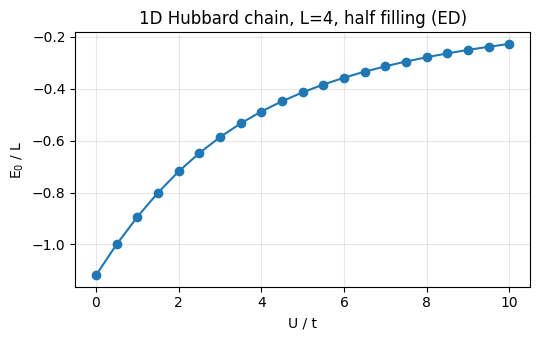

In [14]:
# Ground-state energy vs U/t at half filling (exact diagonalization, L=4)
Us = np.linspace(0, 10, 21)
E_vs_U = []
for u in Us:
    hh, hi = hubbard_terms(L, 1.0, u)
    q = SparsePauliOp.from_sparse_observable(jordan_wigner(hh + hi, n_modes).simplify())
    E_vs_U.append(sector_ground_energy(q, L, (L // 2, L // 2))[0])

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(Us, np.array(E_vs_U) / L, "o-")
ax.set_xlabel("U / t"); ax.set_ylabel("E$_0$ / L")
ax.set_title(f"1D Hubbard chain, L={L}, half filling (ED)")
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 7. Fermionic circuits and gates

A `FermionicCircuit` wraps a `QuantumCircuit`. Its wires are **fermionic modes**, not qubits [[4]](https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/circuit), [[11]](https://quantum.cloud.ibm.com/docs/en/api/qiskit-fermions/circuit).
It accepts only `FermionicGate`s, so it does not depend on a specific encoding. The gate library contains:

| gate | meaning |
|---|---|
| `InitializeModes(occupation)` | prepare an occupation-number basis state (`from_hartree_fock(norb, nelec)` builds the Hartree–Fock state) |
| `OrbitalRotation(U)` | single-particle basis change $a_i^\dagger\mapsto\sum_j U_{ji}a_j^\dagger$ |
| `PrepareSlaterDeterminant(occ, U)` | `InitializeModes` followed by `OrbitalRotation`, with a cheaper synthesis |
| `Evolution(num_modes, H, time)` | $e^{-itH}$ for a Hermitian `FermionOperator`; `time` can be a Qiskit `Parameter` |
| `UCC`, `UCJ` | UCCSD and (L)UCJ ansätze built from ffsim operators (need the `ffsim` extra; see section 10) |

A **Slater determinant** is the antisymmetric product state of a set of occupied orbitals.

HF occupation (block spin): [ True False  True False]
OrderedDict([('InitializeModes', 1), ('OrbitalRotation', 1), ('Evolution', 1)])


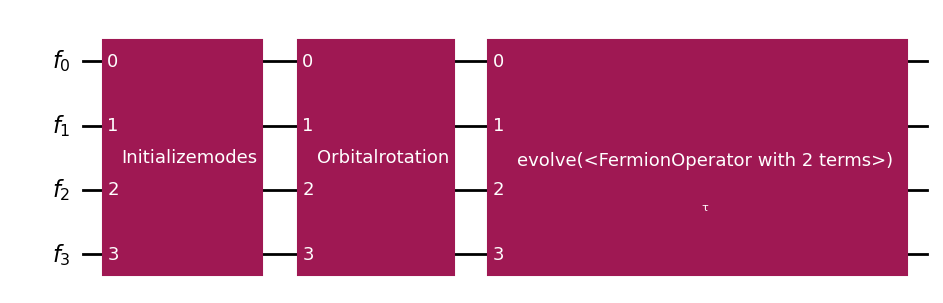

In [15]:
from qiskit.circuit import Parameter
from qiskit_fermions.circuit import FermionicCircuit
from qiskit_fermions.circuit.library import (
    Evolution, InitializeModes, OrbitalRotation, PrepareSlaterDeterminant,
)

hf = InitializeModes.from_hartree_fock(2, (1, 1))     # H2: 2 orbitals, 1 alpha + 1 beta electron
print("HF occupation (block spin):", hf.occupation)

fc = FermionicCircuit(4)
fc.append(hf, fc.register)
fc.append(OrbitalRotation(np.eye(4)), fc.register)
fc.append(Evolution(4, n0 + n1, time=Parameter("τ")), fc.register)
print(fc.count_ops())
fc.draw("mpl", fold=-1)

A product formula can decompose `Evolution` gates **in fermionic space**. The options are `FermionicLieTrotter` (default) and `FermionicSuzukiTrotter` [[19]](https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/fermionic-synthesis).
The decomposition follows the term **groups** of the operator.
`group_terms_by_electronic_structure` assigns groups to a normal-ordered Hamiltonian. Each group is Hermitian, for example a hopping term and its Hermitian conjugate [[20]](https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/grouping).

number of groups: 10 | each group Hermitian: True


decomposed in fermionic space: OrderedDict([('Evolution', 10)])


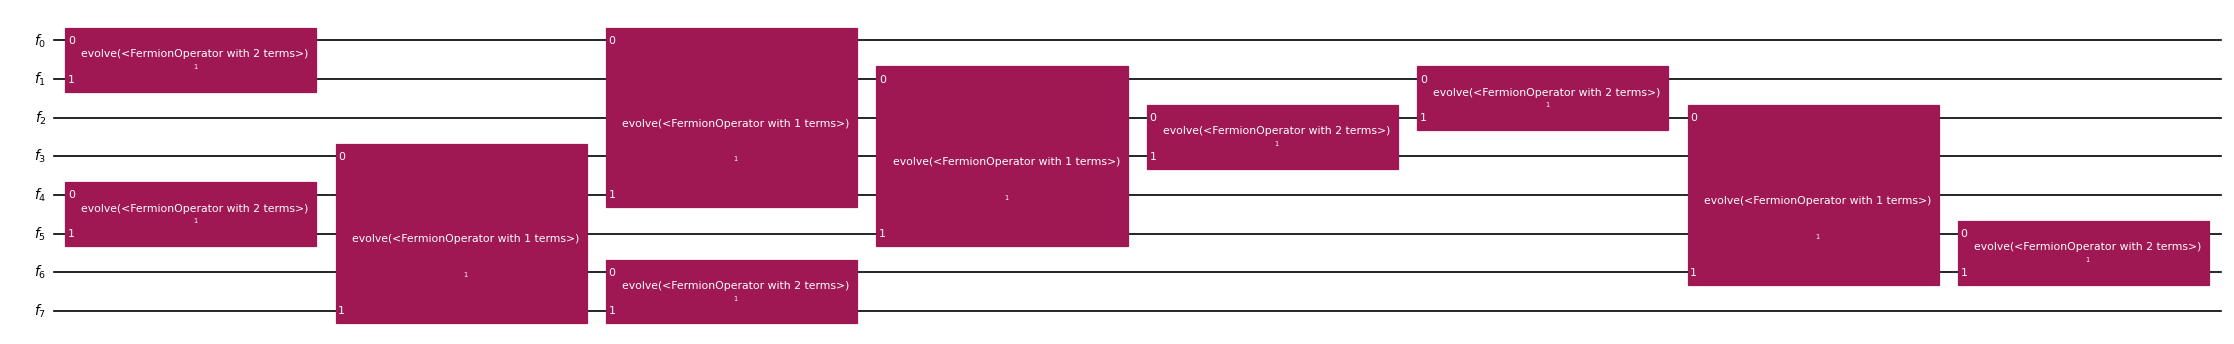

In [16]:
from qiskit_fermions.operators.terms import group_terms_by_electronic_structure, groups_are_hermitian

H_hub_g = H_hub.normal_ordered().simplify(atol=0.0)
group_terms_by_electronic_structure(H_hub_g, n_modes)        # sets H_hub_g.groups in place
print("number of groups:", H_hub_g.num_groups(), "| each group Hermitian:", all(groups_are_hermitian(H_hub_g)))

ev_circ = FermionicCircuit(n_modes)
ev_circ.append(Evolution(n_modes, H_hub_g, time=1.0), ev_circ.register)
print("decomposed in fermionic space:", ev_circ.decompose().count_ops())
ev_circ.decompose().draw("mpl", fold=-1, scale=0.6)

### Givens decompositions

`OrbitalRotation`s are synthesized with Givens rotations [[21]](https://quantum.cloud.ibm.com/docs/en/api/qiskit-fermions/linalg). A **Givens rotation** is a rotation in the plane of two modes.
`qiskit_fermions.linalg.givens_decomposition` uses at most $n(n-1)/2$ rotations on adjacent modes, plus diagonal phases.
`givens_decomposition_slater` is a cheaper version for the preparation of a Slater determinant.

*Note on the installed version:* these Rust functions need a **complex** NumPy array. A real `float64` array raises `TypeError: 'ndarray' object cannot be cast as 'ndarray'`.

In [17]:
from qiskit_fermions.linalg import givens_decomposition

# One-body hopping matrix of the L-site chain; its eigenvectors define the free-fermion orbitals
h1 = -t_hop * (np.eye(L, k=1) + np.eye(L, k=-1))
eps, V = np.linalg.eigh(h1)
rotations, phases = givens_decomposition(V.astype(complex))
print("orbital energies:", np.round(eps, 4))
print(f"{len(rotations)} Givens rotations (max n(n-1)/2 = {L*(L-1)//2}); first one (c, s, i, j):", rotations[0])

orbital energies: [-1.618 -0.618  0.618  1.618]
6 Givens rotations (max n(n-1)/2 = 6); first one (c, s, i, j): (0.8506508083520399, (0.5257311121191337+0j), 1, 0)


## 8. Transpiling fermionic circuits to qubit circuits

The transpiler is a `MultiStagePassManager` with these stages [[5]](https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/transpilation), [[12]](https://quantum.cloud.ibm.com/docs/en/api/qiskit-fermions/transpiler):

`input` (circuit to DAG) → `optimization` (passes at the fermionic level) → `layout` (fermionic register to qubit register, `F2QLayout`) → `synthesis` (`F2QSynthesis`: fermionic gates to qubit gates through a mapping) → `qubit` (a standard Qiskit preset pass manager) → `output`.

`generate_preset_jw_pass_manager(**kwargs)` builds this pipeline for Jordan–Wigner.
It passes `kwargs` (`optimization_level`, `basis_gates`, `backend`, ...) to the Qiskit function `generate_preset_pass_manager` for the qubit stage.
The default fermionic optimization stage runs `MergeOrbitalRotations` and `MergeSlaterDeterminantPreparation`.

input         FermionicCircuitToDAG
optimization  FermionicPassManager
layout        FermionicPassManager
synthesis     F2QSynthesis
qubit         StagedPassManager
output        QuantumDAGToCircuit

fermionic: {'InitializeModes': 1, 'OrbitalRotation': 1, 'Evolution': 1} 
qubit:     {'x': 2, 'rz': 2}


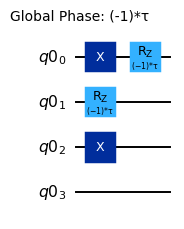

In [18]:
from qiskit_fermions.transpiler.presets import generate_preset_jw_pass_manager

pm = generate_preset_jw_pass_manager(optimization_level=1)
for stage in ("input", "optimization", "layout", "synthesis", "qubit", "output"):
    print(f"{stage:13s}", type(getattr(pm, stage)).__name__)

qc = pm.run(fc)
print("\nfermionic:", dict(fc.count_ops()), "\nqubit:    ", dict(qc.count_ops()))
qc.draw("mpl", fold=-1, scale=0.7)

### Fermionic optimization passes

**Merging** [[6]](https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/merge-slater-determinant). An `InitializeModes` followed by consecutive `OrbitalRotation`s becomes one `PrepareSlaterDeterminant`. Its synthesis uses only the reduced Givens network.
Here we prepare the **exact ground state of the non-interacting ($U=0$) chain**.
We rotate the lowest $L/2$ orbitals of each spin into the eigenvectors $V$ of the hopping matrix.

before: {'OrbitalRotation': 2, 'InitializeModes': 1} 
after:  {'PrepareSlaterDeterminant': 1}
qubit circuit: {'xx_plus_yy': 8, 'x': 4}


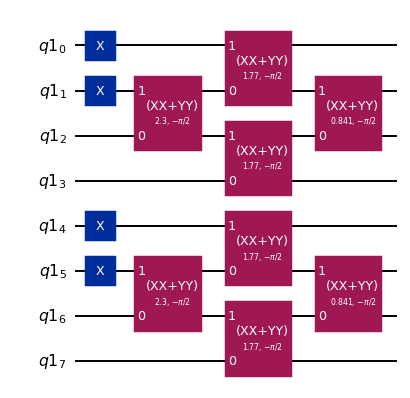

In [19]:
from qiskit_fermions.transpiler import FermionicPassManager
from qiskit_fermions.transpiler.passes import MergeOrbitalRotations, MergeSlaterDeterminantPreparation

U_blk = sla.block_diag(V, V)                         # same rotation for spin-up and spin-down
occ = ([True] * (L // 2) + [False] * (L // 2)) * 2   # lowest L/2 orbitals of each spin

c1 = FermionicCircuit(n_modes)
c1.append(InitializeModes(occ), c1.register)
half = sla.fractional_matrix_power(U_blk, 0.5)       # split the rotation in two, so that the merge pass has two rotations to merge
c1.append(OrbitalRotation(half), c1.register)
c1.append(OrbitalRotation(half), c1.register)
merged = FermionicPassManager([MergeOrbitalRotations(), MergeSlaterDeterminantPreparation()]).run(c1)
print("before:", dict(c1.count_ops()), "\nafter: ", dict(merged.count_ops()))

slater_qc = pm.run(c1)
print("qubit circuit:", dict(slater_qc.count_ops()))
slater_qc.draw("mpl", fold=-1, scale=0.7)

In [20]:
from qiskit.primitives import StatevectorEstimator
est = StatevectorEstimator()

qH_hop = SparsePauliOp.from_sparse_observable(jordan_wigner(H_hop, n_modes).simplify())
qN = SparsePauliOp.from_sparse_observable(
    jordan_wigner(FermionOperator.from_dict({(cre(j), ann(j)): 1.0 for j in range(n_modes)}), n_modes).simplify())
evs = est.run([(slater_qc, [qH_hop, qN, qH_hub])]).result()[0].data.evs
print(f"<H_hop> = {evs[0]:.6f}   exact free-fermion energy 2*sum(eps_occ) = {2*eps[:L//2].sum():.6f}")
print(f"<N>     = {evs[1]:.3f}")
print(f"<H_Hubbard> in this Slater determinant = {evs[2]:.6f}  (ED ground state: {E_hub:.6f})")

<H_hop> = -4.472136   exact free-fermion energy 2*sum(eps_occ) = -4.472136
<N>     = 4.000
<H_Hubbard> in this Slater determinant = -0.472136  (ED ground state: -1.953145)


**Trotterization.** `FermionicTrotterization(synthesis)` applies a fermionic product formula to each `Evolution` gate in the optimization stage.
It can replace the optimization stage of the preset pipeline.
Below we apply $e^{-iHt}$ ($t=1$) to the Slater determinant. We compare the result with the exact evolution, for second-order Suzuki–Trotter with 1, 2, 4 and 8 repetitions.

*Note:* the operator must have Hermitian **groups** (here from `group_terms_by_electronic_structure`). Without groups, the formula splits the operator into single, non-Hermitian terms. The synthesis then fails with `ValueError: Operator contains complex coefficients`.

reps=1: fidelity=0.020827, two-qubit rotations=30, depth=19


reps=2: fidelity=0.853032, two-qubit rotations=60, depth=37
reps=4: fidelity=0.992365, two-qubit rotations=120, depth=73


reps=8: fidelity=0.999551, two-qubit rotations=240, depth=145


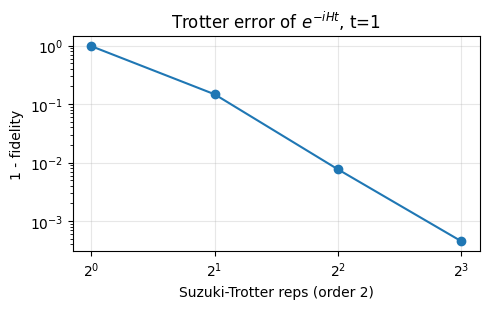

In [21]:
from qiskit.quantum_info import Statevector, Operator
from qiskit_fermions.circuit.library.synthesis import FermionicSuzukiTrotter
from qiskit_fermions.transpiler.passes import FermionicTrotterization

psi0 = Statevector(slater_qc)
psi_exact = psi0.evolve(Operator(sla.expm(-1j * 1.0 * qH_hub.to_matrix())))

rows = []
for reps in (1, 2, 4, 8):
    pm_t = generate_preset_jw_pass_manager(optimization_level=1)
    pm_t.optimization = FermionicPassManager([FermionicTrotterization(FermionicSuzukiTrotter(order=2, reps=reps))])
    qc_t = pm_t.run(ev_circ)
    fid = abs(psi_exact.inner(psi0.evolve(qc_t))) ** 2
    ops = qc_t.count_ops()
    rows.append((reps, fid, sum(v for k, v in ops.items() if k in ("rxx", "ryy", "rzz"))))
    print(f"reps={reps}: fidelity={fid:.6f}, two-qubit rotations={rows[-1][2]}, depth={qc_t.depth()}")

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.semilogy([r[0] for r in rows], [1 - r[1] for r in rows], "o-")
ax.set_xscale("log", base=2); ax.set_xlabel("Suzuki-Trotter reps (order 2)"); ax.set_ylabel("1 - fidelity")
ax.set_title("Trotter error of $e^{-iHt}$, t=1"); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

Other passes in `qiskit_fermions.transpiler.passes`:
* `QDriftTrotterization`: random sampling of evolution terms (qDRIFT; see the SqDRIFT guide [[22]](https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/sqdrift))
* `RelabelModes`: permute the fermionic modes
* `TrivialF2QLayout` / `CustomF2QLayout`: set the layout from the fermionic register to the qubit register. Use a custom layout for encodings with ancilla qubits or a different number of qubits.
* `F2QSynthesis` with plugins (`MapperFnEvolutionSynthesis`, `GivensDecomposition...`): use your own mapping, for example the parity mapper above, through `F2QSynthesisConfig`

## 9. Ground-state energies with `StatevectorEstimator`

The time of an `Evolution` gate can be a Qiskit `Parameter`. After transpilation we therefore get a standard **parameterized qubit circuit**.
We can build variational ansätze at the fermionic level, map them with any encoding, and run them with Qiskit primitives.
This is the variational quantum eigensolver (VQE) approach [[23]](https://qiskit-community.github.io/ffsim/how-to-guides/simulate-vqe.html).

### 9a. H$_2$ with a one-parameter UCC-type ansatz

We start from the Hartree–Fock state $|1010\rangle$ (modes $0_\alpha$ and $0_\beta$ occupied).
We apply $e^{-i\theta G}$ with the Hermitian double-excitation generator $G = i\,(a_{1\alpha}^\dagger a_{1\beta}^\dagger a_{0\beta} a_{0\alpha} - \text{h.c.})$.
For H$_2$ in a minimal basis, this ansatz is exact.

G Hermitian: True
ansatz: {'rz': 61, 'cx': 46, 'sx': 32, 'x': 4} | parameters: ParameterView([Parameter(θ)])


E_HF   = -1.116999 Ha
E_VQE  = -1.137314 Ha at θ = -0.1118
E_ED   = -1.137314 Ha   |error| = 3.33e-15


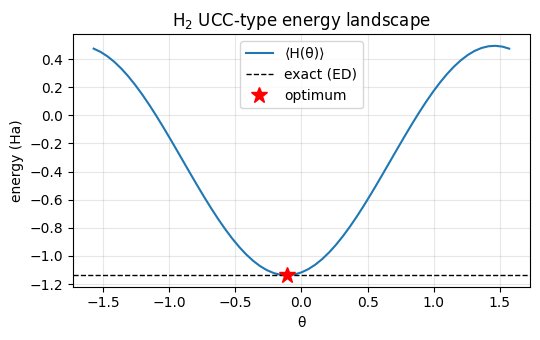

In [22]:
from scipy.optimize import minimize_scalar, minimize

# block-spin modes: 0 = 0alpha, 1 = 1alpha, 2 = 0beta, 3 = 1beta
G = FermionOperator.from_dict({
    (cre(1), cre(3), ann(2), ann(0)): 1j,
    (cre(0), cre(2), ann(3), ann(1)): -1j,
})
print("G Hermitian:", G.is_hermitian())

theta = Parameter("θ")
ansatz_f = FermionicCircuit(4)
ansatz_f.append(InitializeModes.from_hartree_fock(2, (1, 1)), ansatz_f.register)
ansatz_f.append(Evolution(4, G, time=theta), ansatz_f.register)
ansatz_q = generate_preset_jw_pass_manager(
    optimization_level=2, basis_gates=["cx", "rz", "sx", "x"]).run(ansatz_f)
print("ansatz:", dict(ansatz_q.count_ops()), "| parameters:", ansatz_q.parameters)

energy = lambda x: float(est.run([(ansatz_q, qH_h2, [x])]).result()[0].data.evs)
thetas = np.linspace(-np.pi / 2, np.pi / 2, 61)
scan = [energy(x) for x in thetas]
res = minimize_scalar(energy, bounds=(-np.pi / 2, np.pi / 2), method="bounded")
print(f"E_HF   = {energy(0.0):.6f} Ha")
print(f"E_VQE  = {res.fun:.6f} Ha at θ = {res.x:.4f}")
print(f"E_ED   = {E_h2[0]:.6f} Ha   |error| = {abs(res.fun - E_h2[0]):.2e}")

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(thetas, scan, label="⟨H(θ)⟩")
ax.axhline(E_h2[0], color="k", ls="--", lw=1, label="exact (ED)")
ax.plot(res.x, res.fun, "r*", ms=12, label="optimum")
ax.set_xlabel("θ"); ax.set_ylabel("energy (Ha)"); ax.set_title("H$_2$ UCC-type energy landscape")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

### 9b. Fermi–Hubbard with a Hamiltonian variational ansatz (HVA)

The HVA is built from the terms of the Hamiltonian. For the $L=4$ Hubbard chain at half filling, we start from the free-fermion Slater determinant of section 8. We apply $p$ layers of
$$ e^{-i\beta_k H_\text{odd}}\, e^{-i\alpha_k H_\text{even}}\, e^{-i\gamma_k H_U}. $$
$H_\text{even}$ and $H_\text{odd}$ contain the hopping terms on even and odd bonds.
Each factor conserves $N_\uparrow$ and $N_\downarrow$, so the state stays in the correct sector.
Each layer adds three `Evolution` gates with `Parameter` times. We optimize with L-BFGS-B and the exact `StatevectorEstimator`.

In [23]:
import time

def bond_hopping(L, parity, t=1.0):
    d = {}
    for s in (0, L):
        for i in range(parity, L - 1, 2):
            d[(cre(s + i), ann(s + i + 1))] = -t
            d[(cre(s + i + 1), ann(s + i))] = -t
    return FermionOperator.from_dict(d)

H_even, H_odd = bond_hopping(L, 0, t_hop), bond_hopping(L, 1, t_hop)
pm_hva = generate_preset_jw_pass_manager(optimization_level=1)

def hva(p):
    prm = [Parameter(f"x{k}") for k in range(3 * p)]
    c = FermionicCircuit(n_modes)
    c.append(PrepareSlaterDeterminant(occ, U_blk), c.register)
    for k in range(p):
        c.append(Evolution(n_modes, H_int, time=prm[3 * k]), c.register)
        c.append(Evolution(n_modes, H_even, time=prm[3 * k + 1]), c.register)
        c.append(Evolution(n_modes, H_odd, time=prm[3 * k + 2]), c.register)
    return pm_hva.run(c)

hva_results = {}
for p in (1, 2, 3):
    circ = hva(p)
    f = lambda x: float(est.run([(circ, qH_hub, x)]).result()[0].data.evs)
    hist = []
    t0 = time.time()
    r = minimize(f, np.full(3 * p, 0.05), method="L-BFGS-B", callback=lambda xk: hist.append(f(xk)))
    hva_results[p] = (r.fun, hist)
    print(f"p={p}: E={r.fun:.6f}  rel. error={abs((r.fun - E_hub) / E_hub):.3%}  "
          f"2q-rotations={sum(v for k, v in circ.count_ops().items() if k in ('rxx','ryy','rzz','xx_plus_yy'))}  "
          f"evals={r.nfev}  ({time.time()-t0:.1f}s)")
print(f"ED:  E={E_hub:.6f};  Slater determinant (p=0): {evs[2]:.6f}")

p=1: E=-1.686511  rel. error=13.652%  2q-rotations=24  evals=56  (0.2s)


p=2: E=-1.896456  rel. error=2.902%  2q-rotations=40  evals=245  (1.0s)


p=3: E=-1.906395  rel. error=2.394%  2q-rotations=56  evals=910  (4.6s)
ED:  E=-1.953145;  Slater determinant (p=0): -0.472136


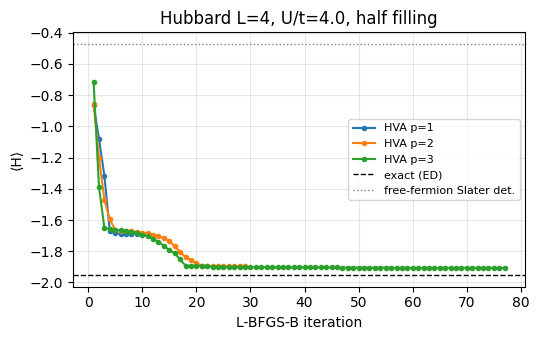

In [24]:
fig, ax = plt.subplots(figsize=(5.5, 3.5))
for p, (e, hist) in hva_results.items():
    ax.plot(range(1, len(hist) + 1), hist, "o-", ms=3, label=f"HVA p={p}")
ax.axhline(E_hub, color="k", ls="--", lw=1, label="exact (ED)")
ax.axhline(evs[2], color="gray", ls=":", lw=1, label="free-fermion Slater det.")
ax.set_xlabel("L-BFGS-B iteration"); ax.set_ylabel("⟨H⟩")
ax.set_title(f"Hubbard L={L}, U/t={U_int}, half filling"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

A larger $p$ recovers more of the correlation energy. The correlation energy is the difference between the Slater-determinant energy and the exact energy.
With this layout, $p \le 3$ does not reach the exact ground state of the $U/t=4$ chain (relative error 2.394% at $p=3$).
Deeper circuits, more parameters (for example one angle per bond) or a better reference state can reduce the error.

## 10. Fermionic-space simulation and ansätze with ffsim

[**ffsim**](https://qiskit-community.github.io/ffsim/) is a simulator for fermionic quantum circuits [[8]](https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/ffsim).
It does not store a $2^{N}$-dimensional qubit statevector.
It works directly in a fixed **(norb, (n$_\alpha$, n$_\beta$)) FCI sector** (FCI: full configuration interaction).
The dimension of this sector is $\binom{n_\text{orb}}{n_\alpha}\binom{n_\text{orb}}{n_\beta}$: 36 instead of 256 for the half-filled 4-site chain.
ffsim also provides ansatz operators (UCJ/LUCJ, UCCSD), molecular-data helpers based on PySCF, and conversion to Qiskit.
qiskit-fermions uses ffsim for simulation. qiskit-fermions itself provides circuits that do not depend on a specific mapping [[8]](https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/ffsim).

The extra (`pip install "qiskit-fermions[ffsim]"`, ffsim 0.0.80 here) enables these features in qiskit-fermions:

| feature | what it does |
|---|---|
| `FermionOperator._linear_operator_(norb, nelec)` | a SciPy `LinearOperator` on the FCI sector, so `ffsim.linear_operator(op, norb=..., nelec=...)` also works |
| `FermionOperator._trace_(norb, nelec)` | trace on the sector (`ffsim.trace`) |
| `FermionicCircuit` / every `FermionicGate`: `_apply_unitary_` | `ffsim.apply_unitary(vec, circuit, norb, nelec)` simulates the fermionic circuit directly |
| `UCJ(ffsim.UCJOp...)`, `UCC(ffsim.UCCSDOp...)` | gates that express the ffsim ansatz operators as `FermionicCircuit`s; any encoding can then map them to qubits |

ffsim does not support Windows, because it depends on PySCF. On Windows, use WSL.

In [25]:
import ffsim
from importlib.metadata import version
from scipy.sparse.linalg import eigsh
from ffsim.qiskit import ffsim_vec_to_qiskit_vec
print("ffsim", version("ffsim"), "| pyscf", version("pyscf"))

ffsim 0.0.80 | pyscf 2.14.0


### 10a. `_linear_operator_` and `_trace_`: sparse ground states

`_linear_operator_` returns a SciPy `LinearOperator` that acts only on the requested sector [[24]](https://qiskit-community.github.io/ffsim/api/stubs/ffsim.linear_operator.html).
A sparse Lanczos solver (`eigsh`) then finds the ground state without the Jordan–Wigner matrix.
ffsim requires that the operator conserves both $N$ and $S_z$. Both of our Hamiltonians do.

In [26]:
norb_hub, nelec_hub = L, (L // 2, L // 2)
lin_hub = H_hub._linear_operator_(norb_hub, nelec_hub)       # same as ffsim.linear_operator(H_hub, norb=..., nelec=...)
lin_h2 = H_h2._linear_operator_(2, (1, 1))
print("Hubbard sector dimension:", lin_hub.shape, " vs. qubit Hilbert space", 2 ** n_modes)

E_hub_ffsim, gs_hub = eigsh(lin_hub, k=1, which="SA")
E_h2_ffsim = eigsh(lin_h2, k=1, which="SA")[0][0]
print(f"Hubbard: eigsh = {E_hub_ffsim[0]:.10f}   JW-sector ED = {E_hub:.10f}")
print(f"H2:      eigsh = {E_h2_ffsim:.10f}   JW-sector ED = {E_h2[0]:.10f}")

# Trace on the sector, checked against the trace of the JW matrix restricted to the same sector
idx = sector_indices(L, *nelec_hub)
tr_jw = qH_hub.to_matrix(sparse=True)[idx][:, idx].diagonal().sum().real
print(f"trace: _trace_ = {H_hub._trace_(norb_hub, nelec_hub).real:.6f}   JW sector trace = {tr_jw:.6f}"
      f"   (ffsim.trace: {ffsim.trace(H_hub, norb=norb_hub, nelec=nelec_hub).real:.6f})")

Hubbard sector dimension: (36, 36)  vs. qubit Hilbert space 256
Hubbard: eigsh = -1.9531453087   JW-sector ED = -1.9531453087
H2:      eigsh = -1.1373139545   JW-sector ED = -1.1373139545
trace: _trace_ = 144.000000   JW sector trace = 144.000000   (ffsim.trace: 144.000000)


### 10b. Simulating a `FermionicCircuit` in fermionic space

`ffsim.apply_unitary(vec, circuit, norb, nelec)` applies a `FermionicCircuit` to an ffsim state vector, gate by gate [[13]](https://qiskit-community.github.io/ffsim/api/stubs/ffsim.apply_unitary.html). In this simulation:
* `InitializeModes` (and the initial-state part of `PrepareSlaterDeterminant`) only **checks** that the input vector has the declared occupation. It does not prepare the state. We therefore start from `ffsim.hartree_fock_state`. This state fills the lowest-indexed orbitals of each spin, so it matches `occ`.
* `Evolution` is applied **exactly**, with no Trotter error.

`ffsim.qiskit.ffsim_vec_to_qiskit_vec` embeds the sector vector in the $2^N$-dimensional Jordan–Wigner qubit space [[25]](https://qiskit-community.github.io/ffsim/api/ffsim.qiskit.html). We use it to compare with qubit simulations.

In [27]:
t_ev = 0.7
fc_sim = FermionicCircuit(n_modes)
fc_sim.append(InitializeModes(occ), fc_sim.register)
fc_sim.append(OrbitalRotation(U_blk), fc_sim.register)          # -> free-fermion ground state
fc_sim.append(Evolution(n_modes, H_hub_g, time=t_ev), fc_sim.register)

vec0 = ffsim.hartree_fock_state(norb_hub, nelec_hub)
vec_f = ffsim.apply_unitary(vec0, fc_sim, norb_hub, nelec_hub)     # fermionic-space simulation
vec_f_qubit = ffsim_vec_to_qiskit_vec(vec_f, norb_hub, nelec_hub)

# Reference 1: JW-mapped Slater-determinant circuit, then exact exp(-i t H_JW) on 2^8 amplitudes
psi_ref = Statevector(slater_qc).evolve(Operator(sla.expm(-1j * t_ev * qH_hub.to_matrix())))
print(f"|<JW exact | ffsim>|^2           = {abs(np.vdot(psi_ref.data, vec_f_qubit))**2:.12f}")

# Reference 2: the same FermionicCircuit transpiled with JW (with and without fermionic Trotterization)
for reps in (None, 4, 16):
    pm_r = generate_preset_jw_pass_manager(optimization_level=1)
    if reps:
        pm_r.optimization = FermionicPassManager(
            [MergeOrbitalRotations(), MergeSlaterDeterminantPreparation(),
             FermionicTrotterization(FermionicSuzukiTrotter(order=2, reps=reps))])
    psi_q = Statevector(pm_r.run(fc_sim))
    label = "no fermionic Trotterization" if reps is None else f"Suzuki-2, reps={reps}"
    print(f"|<JW circuit ({label:28s}) | ffsim>|^2 = {abs(np.vdot(psi_q.data, vec_f_qubit))**2:.6f}")

# InitializeModes really is a check: a wrong input state is rejected
try:
    ffsim.apply_unitary(ffsim.hartree_fock_state(norb_hub, (1, 3)), fc_sim, norb_hub, (1, 3))
except ValueError as err:
    print("\nValueError:", str(err)[:110], "...")

|<JW exact | ffsim>|^2           = 1.000000000000
|<JW circuit (no fermionic Trotterization ) | ffsim>|^2 = 0.033647
|<JW circuit (Suzuki-2, reps=4            ) | ffsim>|^2 = 0.997639


|<JW circuit (Suzuki-2, reps=16           ) | ffsim>|^2 = 0.999991

ValueError: InitializeModes: the state vector has amplitude outside the alpha-sector subspace defined by its occupation fo ...


The ffsim result agrees with the exact evolution of the JW statevector to machine precision (overlap 1.000000000000).
Without fermionic Trotterization, the transpiled circuit maps the whole `Evolution` to one `PauliEvolutionGate` with one Lie–Trotter step. Its fidelity is 0.033647.
With Suzuki–Trotter repetitions, the result converges to the ffsim result: 0.997639 for 4 repetitions and 0.999991 for 16.

### 10c. UCCSD on H$_2$ with the `UCC` gate

`UCC` wraps an ffsim UCCSD operator (unitary coupled cluster with singles and doubles) [[26]](https://qiskit-community.github.io/ffsim/api/stubs/ffsim.UCCSDOpRestrictedReal.html).
`ffsim.UCCSDOpRestrictedReal.from_parameters(x, norb, nocc)` converts a flat parameter vector into the operator. An optimizer needs this form.
For H$_2$ ($n_\text{orb}=2$, $n_\text{occ}=1$) there are 2 parameters: one single and one double amplitude.
We compute the energy in fermionic space with `apply_unitary` and `_linear_operator_`.
After the optimization, we transpile the optimal circuit with JW and check it with `StatevectorEstimator`.

*Note on the installed version:* the JW preset has no synthesis plugin for `UCC`/`UCJ` gates (`TypeError: No plugin registered ...`). Call `FermionicCircuit.decompose()` first. It expands these gates into `OrbitalRotation`/`Evolution` gates, which the preset supports.

In [28]:
from qiskit_fermions.circuit.library import UCC, UCJ

norb_h2, nelec_h2, nocc_h2 = 2, (1, 1), 1
hf_h2 = ffsim.hartree_fock_state(norb_h2, nelec_h2)
n_ucc = ffsim.UCCSDOpRestrictedReal.n_params(norb=norb_h2, nocc=nocc_h2)

def ucc_circuit(x):
    c = FermionicCircuit(2 * norb_h2)
    c.append(InitializeModes.from_hartree_fock(norb_h2, nelec_h2), c.register)
    c.append(UCC(ffsim.UCCSDOpRestrictedReal.from_parameters(x, norb=norb_h2, nocc=nocc_h2)), c.register)
    return c

def ucc_energy(x):
    psi = ffsim.apply_unitary(hf_h2, ucc_circuit(x), norb_h2, nelec_h2)
    return float(np.vdot(psi, lin_h2 @ psi).real)

res_ucc = minimize(ucc_energy, np.zeros(n_ucc), method="L-BFGS-B")
print(f"UCCSD parameters: {n_ucc};  optimum x = {np.round(res_ucc.x, 5)}")
print(f"E_UCCSD (ffsim)  = {res_ucc.fun:.10f} Ha")
print(f"E_ED             = {E_h2[0]:.10f} Ha   |error| = {abs(res_ucc.fun - E_h2[0]):.1e}")

# Transpile the optimal UCCSD circuit with JW and evaluate on the qubit Hamiltonian
qc_ucc = generate_preset_jw_pass_manager(optimization_level=2, basis_gates=["cx", "rz", "sx", "x"]).run(
    ucc_circuit(res_ucc.x).decompose())
E_ucc_q = float(est.run([(qc_ucc, qH_h2)]).result()[0].data.evs)
print(f"E (JW circuit, StatevectorEstimator) = {E_ucc_q:.10f} Ha;  gates: {dict(qc_ucc.count_ops())}")

UCCSD parameters: 2;  optimum x = [ 0.      -0.11181]
E_UCCSD (ffsim)  = -1.1373139545 Ha
E_ED             = -1.1373139545 Ha   |error| = 1.8e-15
E (JW circuit, StatevectorEstimator) = -1.1373139545 Ha;  gates: {'rz': 61, 'cx': 46, 'sx': 32, 'x': 4}


The JW circuit gives the same energy as ffsim.
In general the two can differ. The circuit definition of `UCC` is a first-order Trotter product of the single and double excitations, which do not commute. ffsim applies $e^{T-T^\dagger}$ exactly.
Here the optimal single amplitude is zero by symmetry, so the product is exact.

### 10d. LUCJ for H$_2$ from PySCF CCSD amplitudes

The unitary cluster Jastrow (UCJ) ansatz [[15]](https://qiskit-community.github.io/ffsim/api/stubs/ffsim.UCJOpSpinBalanced.html) is often initialized from coupled-cluster amplitudes. The local version (LUCJ) [[14]](https://qiskit-community.github.io/ffsim/explanations/lucj.html) keeps only the interactions that match the qubit connectivity.
Here PySCF [[16]](https://pyscf.org/user/scf.html), [[17]](https://pyscf.org/user/cc.html) runs RHF and CCSD for H$_2$/STO-3G.
`ffsim.MolecularData` [[27]](https://qiskit-community.github.io/ffsim/api/stubs/ffsim.MolecularData.html) collects the integrals and writes them to an FCIDUMP file. `qiskit_fermions` reads this file, so the two packages work together.
`UCJOpSpinBalanced.from_t_amplitudes` then builds the ansatz from the double-factorized $t_2$ amplitudes, with $t_1$ as a final orbital rotation [[15]](https://qiskit-community.github.io/ffsim/api/stubs/ffsim.UCJOpSpinBalanced.html).

In [29]:
from pyscf import gto, scf, cc

mol = gto.M(atom="H 0 0 0; H 0 0 0.735", basis="sto-3g", verbose=0)
mf = scf.RHF(mol).run()
ccsd = cc.CCSD(mf).run()
mol_data = ffsim.MolecularData.from_scf(mf)

fcidump_path = os.path.join(tempfile.mkdtemp(), "h2_pyscf.fcidump")
mol_data.to_fcidump(fcidump_path)
H_h2_pyscf = FermionOperator.from_fcidump(FCIDump.from_file(fcidump_path))
lin_h2_pyscf = H_h2_pyscf._linear_operator_(norb_h2, nelec_h2)
E_fci_pyscf = eigsh(lin_h2_pyscf, k=1, which="SA")[0][0]

ucj_h2 = ffsim.UCJOpSpinBalanced.from_t_amplitudes(ccsd.t2, t1=ccsd.t1, n_reps=1)
c_ucj = FermionicCircuit(2 * norb_h2)
c_ucj.append(InitializeModes.from_hartree_fock(norb_h2, nelec_h2), c_ucj.register)
c_ucj.append(UCJ(ucj_h2), c_ucj.register)
psi = ffsim.apply_unitary(hf_h2, c_ucj, norb_h2, nelec_h2)
print(f"RHF  = {mf.e_tot:.8f}   CCSD = {ccsd.e_tot:.8f}   FCI (eigsh on FCIDump op) = {E_fci_pyscf:.8f} Ha")
print(f"UCJ(n_reps=1) from CCSD amplitudes, no optimization: {np.vdot(psi, lin_h2_pyscf @ psi).real:.8f} Ha")
print("UCJ gate:", UCJ(ucj_h2).norb, "orbitals,", UCJ(ucj_h2).num_modes, "modes,", UCJ(ucj_h2).n_reps, "rep;",
      "decomposes into", dict(c_ucj.decompose().count_ops()))

RHF  = -1.11699900   CCSD = -1.13730619   FCI (eigsh on FCIDump op) = -1.13730604 Ha
UCJ(n_reps=1) from CCSD amplitudes, no optimization: -1.13225596 Ha
UCJ gate: 2 orbitals, 4 modes, 1 rep; decomposes into {'OrbitalRotation': 6, 'InitializeModes': 1, 'Evolution': 1}


### 10e. LUCJ VQE on the Hubbard chain

Now we use a variational **local** UCJ (LUCJ) ansatz [[14]](https://qiskit-community.github.io/ffsim/explanations/lucj.html) for the $L=4$ chain [[7]](https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/lucj).
The `interaction_pairs` keep only diagonal-Coulomb terms between same-spin nearest neighbours and between opposite spins on the same site. This matches the lattice.
The reference state is the free-fermion Slater determinant of section 8. The full state is computed in the 36-dimensional sector.
We optimize the energy with L-BFGS-B. Here L-BFGS-B uses finite-difference gradients.
We then transpile the optimum with JW and check it with `StatevectorEstimator`.

In [30]:
pairs = ([(p, p + 1) for p in range(L - 1)], [(p, p) for p in range(L)])     # (alpha-alpha, alpha-beta)
ref_hub = PrepareSlaterDeterminant(occ, U_blk)

def lucj_circuit(x, n_reps):
    op_ = ffsim.UCJOpSpinBalanced.from_parameters(x, norb=L, n_reps=n_reps, interaction_pairs=pairs)
    c = FermionicCircuit(n_modes)
    c.append(ref_hub, c.register)
    c.append(UCJ(op_), c.register)
    return c

def lucj_energy(x, n_reps):
    op_ = ffsim.UCJOpSpinBalanced.from_parameters(x, norb=L, n_reps=n_reps, interaction_pairs=pairs)
    psi = ffsim.apply_unitary(vec_ref_hub, op_, norb_hub, nelec_hub)
    return float(np.vdot(psi, lin_hub @ psi).real)

# reference vector = free-fermion Slater determinant, computed once by simulating the fermionic gate
vec_ref_hub = ffsim.apply_unitary(vec0, ref_hub, norb_hub, nelec_hub)

lucj_results = {}
for n_reps in (1, 2):
    n_par = ffsim.UCJOpSpinBalanced.n_params(L, n_reps, interaction_pairs=pairs)
    hist = []
    t0 = time.time()
    r = minimize(lucj_energy, np.random.default_rng(0).normal(scale=0.01, size=n_par), args=(n_reps,),
                 method="L-BFGS-B", options={"maxfun": 3000},
                 callback=lambda xk: hist.append(lucj_energy(xk, n_reps)))
    lucj_results[n_reps] = (r, hist)
    print(f"LUCJ n_reps={n_reps}: {n_par} params, E = {r.fun:.6f}, rel. error = {abs((r.fun-E_hub)/E_hub):.3%}, "
          f"{r.nfev} evals ({time.time()-t0:.1f}s)")

# Cross-check: the full FermionicCircuit (Slater prep + UCJ gate), simulated directly, and transpiled with JW
best = lucj_results[2][0]
c_best = lucj_circuit(best.x, 2)
psi_c = ffsim.apply_unitary(vec0, c_best, norb_hub, nelec_hub)
qc_best = generate_preset_jw_pass_manager(optimization_level=1).run(c_best.decompose())
E_q = float(est.run([(qc_best, qH_hub)]).result()[0].data.evs)
print(f"\nFermionicCircuit via ffsim: {np.vdot(psi_c, lin_hub @ psi_c).real:.6f};  "
      f"JW circuit via StatevectorEstimator: {E_q:.6f};  ED: {E_hub:.6f}")
print("JW circuit gates:", dict(qc_best.count_ops()))

LUCJ n_reps=1: 23 params, E = -1.834327, rel. error = 6.083%, 2544 evals (13.2s)


LUCJ n_reps=2: 46 params, E = -1.929264, rel. error = 1.223%, 3008 evals (20.4s)



FermionicCircuit via ffsim: -1.929264;  JW circuit via StatevectorEstimator: -1.929264;  ED: -1.953145
JW circuit gates: {'xx_plus_yy': 44, 'p': 22, 'rzz': 20, 'rz': 14, 'x': 4, 'u1': 2}


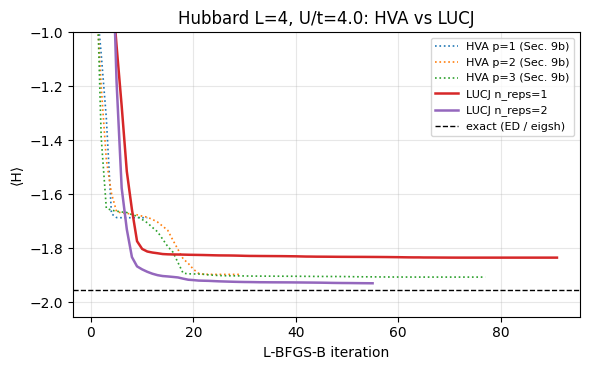

In [31]:
fig, ax = plt.subplots(figsize=(6, 3.8))
for p, (e, hist) in hva_results.items():
    ax.plot(range(1, len(hist) + 1), hist, ":", lw=1.2, label=f"HVA p={p} (Sec. 9b)")
for n_reps, (r, hist) in lucj_results.items():
    ax.plot(range(1, len(hist) + 1), hist, "-", lw=1.8, label=f"LUCJ n_reps={n_reps}")
ax.axhline(E_hub, color="k", ls="--", lw=1, label="exact (ED / eigsh)")
ax.set_xlabel("L-BFGS-B iteration"); ax.set_ylabel("⟨H⟩"); ax.set_ylim(E_hub - 0.1, -1.0)
ax.set_title(f"Hubbard L={L}, U/t={U_int}: HVA vs LUCJ"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

LUCJ has more parameters than our HVA (46 for two repetitions). With two repetitions, its energy is within 1.223% of the exact ground-state energy.
The optimizer stopped at the `maxfun` limit. A longer run or analytic gradients can improve the result.
The same `FermionicCircuit` can be simulated in fermionic space with ffsim, or mapped to qubits with any mapping.

## 11. Summary and references

* **Operators:** `FermionOperator.from_dict` with `cre`/`ann`; `+`, `@`, `&`, `.adjoint()`. `.simplify()` merges duplicate terms. `.normal_ordered()` applies the CAR. `commutator`/`anti_commutator` are in `operators.library`. `MajoranaOperator` and `fermion_to_majorana` give the Majorana representation.
* **Hamiltonians:** build lattice models directly, or load molecules with `FCIDump.from_file` and `FermionOperator.from_fcidump`. `group_terms_by_electronic_structure` adds Hermitian term groups.
* **Mappings:** `jordan_wigner(op, n)` returns a `SparseObservable`. `map_fermion_action_generators` builds new encodings, for example the parity mapper above.
* **Circuits:** `FermionicCircuit` with `InitializeModes`, `OrbitalRotation`, `PrepareSlaterDeterminant` and `Evolution` (parameterizable). `UCC`/`UCJ` wrap the ffsim UCCSD/UCJ operators.
* **Transpiler:** `generate_preset_jw_pass_manager` runs fermionic optimizations (`MergeOrbitalRotations`, `MergeSlaterDeterminantPreparation`, `FermionicTrotterization`, `QDriftTrotterization`), then layout, synthesis and the standard Qiskit qubit pipeline.
* **Ground states:** exact diagonalization in a particle-number sector, and VQE-type optimization of fermionic ansätze with `StatevectorEstimator`.
* **ffsim:** `_linear_operator_` with `eigsh` for sparse ground states, `_trace_`, and `ffsim.apply_unitary` on full `FermionicCircuit`s (exact, in the sector, equal to the JW statevector result). UCCSD (`UCC`) reached the exact H$_2$ energy. LUCJ (`UCJ`, which can start from PySCF CCSD amplitudes) reached 1.223% relative error for the Hubbard chain.

### Notes on the installed version (qiskit-fermions 0.2.0)
* `simplify()` does not apply the fermionic algebra. Terms such as $a_0^\dagger a_0^\dagger a_0 a_0$ remain. Workaround: call `normal_ordered()`.
* `givens_decomposition` fails with a real array. Workaround: pass a complex array (`V.astype(complex)`).
* Trotterization of an `Evolution` whose operator has no `groups` fails at synthesis with a "complex coefficients" error. Workaround: add groups with `group_terms_by_electronic_structure`.
* `FermionOperator._linear_operator_`/`_trace_`, `UCC`, `UCJ` and `ffsim.apply_unitary` on fermionic circuits need the **ffsim** extra (`pip install "qiskit-fermions[ffsim]"`; not available on Windows).
* The JW preset pass manager has no synthesis plugin for `UCC`/`UCJ` (`TypeError: No plugin registered ...`). Workaround: call `.decompose()` on the `FermionicCircuit` before transpilation.
* In ffsim simulation, `InitializeModes` only checks the occupation of the input vector and does not prepare it. Workaround: start from a matching state, for example `ffsim.hartree_fock_state`. `Evolution` and `UCC` are applied exactly, so the transpiled (Trotterized) circuits can give slightly different results.

### References

1. qiskit-fermions guide: Overview. <https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/overview>
2. qiskit-fermions guide: Design principles of operator representations. <https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/operators>
3. qiskit-fermions guide: Map operator representations. <https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/mappers>
4. qiskit-fermions guide: Work with fermionic circuits. <https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/circuit>
5. qiskit-fermions guide: Transpile fermionic circuits. <https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/transpilation>
6. qiskit-fermions guide: Optimize Slater determinant preparation. <https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/merge-slater-determinant>
7. qiskit-fermions guide: Transpile an LUCJ ansatz. <https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/lucj>
8. qiskit-fermions guide: How this package relates to ffsim. <https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/ffsim>
9. qiskit-fermions API reference: `operators`. <https://quantum.cloud.ibm.com/docs/en/api/qiskit-fermions/operators>
10. qiskit-fermions API reference: `mappers`. <https://quantum.cloud.ibm.com/docs/en/api/qiskit-fermions/mappers>
11. qiskit-fermions API reference: `circuit`. <https://quantum.cloud.ibm.com/docs/en/api/qiskit-fermions/circuit>
12. qiskit-fermions API reference: `transpiler`. <https://quantum.cloud.ibm.com/docs/en/api/qiskit-fermions/transpiler>
13. ffsim API reference: `ffsim.apply_unitary`. <https://qiskit-community.github.io/ffsim/api/stubs/ffsim.apply_unitary.html>
14. ffsim explanation: The local unitary cluster Jastrow (LUCJ) ansatz. <https://qiskit-community.github.io/ffsim/explanations/lucj.html>
15. ffsim API reference: `ffsim.UCJOpSpinBalanced`. <https://qiskit-community.github.io/ffsim/api/stubs/ffsim.UCJOpSpinBalanced.html>
16. PySCF user guide: Self-consistent field (SCF) methods. <https://pyscf.org/user/scf.html>
17. PySCF user guide: Coupled-cluster theory. <https://pyscf.org/user/cc.html>
18. ffsim API reference: `ffsim.fermi_hubbard_1d`. <https://qiskit-community.github.io/ffsim/api/stubs/ffsim.fermi_hubbard_1d.html>
19. qiskit-fermions guide: Synthesize an Evolution gate in fermionic space. <https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/fermionic-synthesis>
20. qiskit-fermions guide: Group operator terms. <https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/grouping>
21. qiskit-fermions API reference: `linalg`. <https://quantum.cloud.ibm.com/docs/en/api/qiskit-fermions/linalg>
22. qiskit-fermions guide: Generate SqDRIFT circuits. <https://quantum.cloud.ibm.com/docs/en/addons/qiskit-fermions/guides/sqdrift>
23. ffsim how-to: Simulate the variational quantum eigensolver (VQE). <https://qiskit-community.github.io/ffsim/how-to-guides/simulate-vqe.html>
24. ffsim API reference: `ffsim.linear_operator`. <https://qiskit-community.github.io/ffsim/api/stubs/ffsim.linear_operator.html>
25. ffsim API reference: `ffsim.qiskit`. <https://qiskit-community.github.io/ffsim/api/ffsim.qiskit.html>
26. ffsim API reference: `ffsim.UCCSDOpRestrictedReal`. <https://qiskit-community.github.io/ffsim/api/stubs/ffsim.UCCSDOpRestrictedReal.html>
27. ffsim API reference: `ffsim.MolecularData`. <https://qiskit-community.github.io/ffsim/api/stubs/ffsim.MolecularData.html>